# Part 5: Predictor Selection {-}

In [1]:
import warnings
import numpy as np
warnings.filterwarnings(action='ignore')

The process of **predictor selection** in regression consists of
making a decision among all of the possible subsets of predictors
to find that model with the best ability to **generalize** to the
population from which the training sample was drawn.

Various criterion have been proposed for comparing models.

A standard tool is the **Akaike Information Criterion (AIC)**,
often defined in the context of linear regression as 
\begin{equation*}
\mbox{AIC} = n \log(\mbox{RSS}) + 2p
\end{equation*}
where $p$ is the number of $\beta$ parameters in the model.

It is possible to show that this criterion is optimal in a particular
sense when the irreducible errors $\epsilon$ are iid normal, but
it is still typical to see
it used in more general situations. Nevertheless, if the errors are
far from normal, the validity of this form for AIC should be questioned.

\newpage

**Exercise:** How does the definition of AIC balance model fit with model complexity?

\answerlines{7}


**Technical Comment:** 

It is only the ordering of the models that AIC provides which is important.
Different texts and software packages use different definitions of AIC in
the context of linear regression, but in all cases these expressions
should be a monotonically increasing function of the definition given above.

To be more concrete, the value of AIC reported by Python for the Fama-French model fit to PNC data in Part 4 is 350.383. (This was found via `ff3modPNC.aic`.) But, in this case,
\begin{equation*}
n \log(\mbox{RSS}) + 2p = 593.223. 
\end{equation*}
These differ by the irrelevant amount $n (\log(2\pi/n) +1)$.

\newpage

## Example (Section 11.3 in Ruppert and Matteson) {-}

The **forward rate function** $r(t)$ returns the current forecast of
bond interest rates at time $t$ in the future.
The current price of of a zero-coupon bond with maturity $T$ can be
found by discounting the face value of the bond by the forward rates
"averaged" over the period until maturity:
\begin{equation*}
   P(T) = \mbox{Face Value of Bond} \times \exp\!\left(-\!\int_0^T \!r(t) \; dt\right)
\end{equation*}
(The face value of the bond is the amount to be paid to the holder
at maturity.)

Simple derivation shows that
\begin{equation*}
  r(T) = -\frac{\partial}{\partial T} \log P(T).
\end{equation*}

Hence, we can estimate $r(t)$ using current zero-coupon bond
prices.

In particular, consider a grid of observable maturity dates
$T_0 < T_1 < \cdots < T_n$ and approximate the derivative of $\log P(T)$
at $T_i$ using
\begin{equation*}
    \frac{\log(P(T_i)) - \log(P(T_{i-1}))}{T_i - T_{i-1}}
\end{equation*}
for $i=1,2,\ldots,n$.

This sets up a natural regression problem where the response is
\begin{equation*}
    Y_i = -\frac{\log(P(T_i)) - \log(P(T_{i-1}))}{T_i - T_{i-1}}
\end{equation*}
and our simple model assumes that
\begin{equation*}
    Y_i = r(T_i) + \epsilon_i
\end{equation*}
where the $\epsilon_i$ are mean zero, uncorrelated irreducible errors. Hence, in this example
we have a single predictor, time to maturity $(T)$.

\newpage

The data we have can be read in and visualized as follows. (Note that the first two lines were needed to avoid problems with SSL certificate verification.)

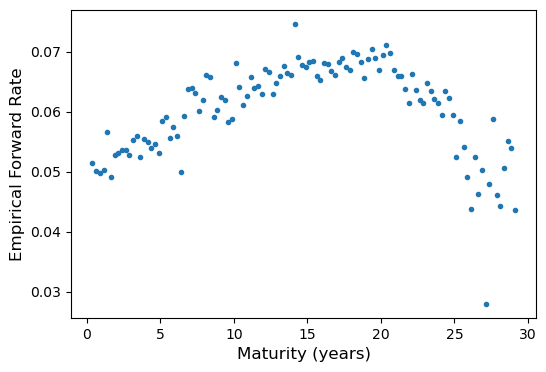

In [2]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

import pandas as pd
import matplotlib.pyplot as plt

forratedat = pd.read_csv("http://www.stat.cmu.edu/~cschafer/MSCF/forratedat.txt",sep=" ")

fig, axs = plt.subplots(1, 1, figsize=[6,4])
axs.plot(forratedat['maturity'],forratedat['emp'], marker='.', ms=6, linestyle="none")
axs.set_xlabel("Maturity (years)", size=12)
axs.set_ylabel("Empirical Forward Rate", size=12)
plt.show()

We will consider polynomial models of the form
\begin{equation*}
   Y_i = \sum_{j=0}^p \beta_j T_i^j + \epsilon_i
\end{equation*}
with a goal of finding the best subset of the $p$ polynomial terms to include
in the model. (As is usually the case, 
we do not consider removing the intercept $\beta_0$.)

The "full" model (largest possible model) we'll consider includes up to
the ninth power.

\newpage

We will **scale** maturity to have mean zero and variance one:

In [3]:
forratedat['maturity'] = (forratedat['maturity'] - forratedat['maturity'].mean()) / (forratedat['maturity'].std())

**Exercise:** Why is scaling the predictor a good idea in this case?

\answerlines{7}

\newpage 

Now, we can fit the full model:

In [4]:
from sklearn.preprocessing import PolynomialFeatures

polynomial_features= PolynomialFeatures(degree=9)

Xfull_with_ones = polynomial_features.fit_transform(np.array(forratedat['maturity']).reshape(-1, 1))

Xfull = pd.DataFrame(Xfull_with_ones).drop(0,axis=1)

import statsmodels.api as sm

fullmod = sm.OLS(endog=forratedat['emp'],exog=Xfull_with_ones).fit()

**Exercise:** Inspect `fullmod.summary()` and comment on the parameter estimates and the t-statistics. Do you think that this model actually needs this many terms, or are we at risk of overfitting?

\answerlines{6}

\newpage

## Exhaustive Search {-}

In cases where the number of predictors is small, an exhaustive search
over all possible models is possible.

**Exercise:** If a model has $p$ candidate predictors, how many models are compared in the exhaustive search?

\answerlines{1}

The code below illustrates an exhaustive search.

In [5]:
import itertools
from tqdm import tnrange, tqdm_notebook

df = {}

for k in tnrange(1, len(Xfull.columns)+1):
    for combo in itertools.combinations(Xfull.columns, k):
        X_with_ones = sm.add_constant(Xfull[list(combo)])
        model = sm.OLS(endog=forratedat['emp'], exog=X_with_ones).fit()
        df[str(combo)] = model.aic
        
df = pd.Series(df)

  0%|          | 0/9 [00:00<?, ?it/s]

\newpage

The powers included in the optimal model are below.

In [6]:
df.idxmin()

'(1, 4, 5, 6, 7)'

**Exercise:** Parse the Python code in the previous example.

\answerlines{18}

\newpage

If you look at `df.idxmin()`, we see that the AIC-optimal model is
\begin{equation*}
   Y_i = \beta_0 + \beta_1 T_i + \beta_4 T_i^4 + \beta_5 T_i^5 + \beta_6 T_i^6 + \beta_7 T_i^7 + \epsilon_i
\end{equation*}
Let's fit that model.

**Exercise:** Which fit has a larger value of $R^2$, the AIC-optimal model, or the full model?

\answerlines{3}

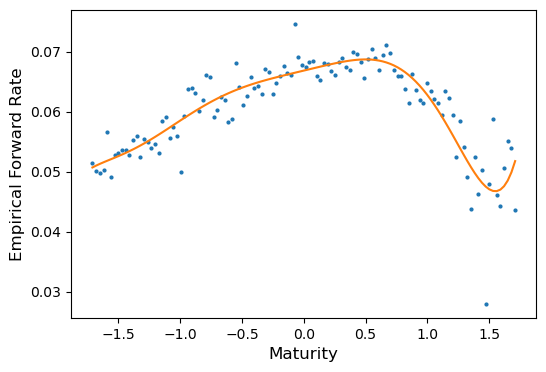

In [7]:
X_with_ones = Xfull_with_ones[:,[0,1,4,5,6,7]]

AICoptmodel = sm.OLS(endog=forratedat['emp'],exog=X_with_ones).fit()

fig, axs = plt.subplots(1, 1, figsize=[6,4])
axs.plot(forratedat['maturity'],forratedat['emp'],marker='.', ms=4, linestyle="none")
axs.set_xlabel("Maturity", size=12)
axs.set_ylabel("Empirical Forward Rate", size=12)
axs.plot(forratedat['maturity'],AICoptmodel.fittedvalues,ms=10)
plt.show()

**Exercise:** Comment on the quality of the fit of the model.

\answerlines{5}

\newpage

## Stepwise Regression {-}

An exhaustive search is not feasible when there is a large number of
predictors.

A classic strategy for dealing with the large number of possible models
is to use a **stepwise selection** procedure.

With this method, one (typically) starts with the largest model under consideration,
and then takes a sequence of **steps**: At each step one predictor is 
either **added** or **dropped**, depending on if a **forward** or **backward** selection
procedure is used, respecitvely.

The decision for which step to take (i.e., which predictor to add or
drop) is based on AIC: You take the step which reduces AIC the most.

Once AIC no longer changes, the process stops, and you have your final
model.

This algorithm is far from perfect, but is useful in the appropriate 
situations.

\newpage

In [8]:
features_chosen = []
remaining_features = list(Xfull.columns.values)
best_AIC = np.inf

for i in range(1, len(Xfull.columns)+1):
    add_feature = False
    
    for combo in itertools.combinations(remaining_features, 1):
        X_with_ones = sm.add_constant(Xfull[list(combo) + features_chosen])
        model = sm.OLS(endog=forratedat['emp'], exog=X_with_ones).fit()
        this_AIC = model.aic

        if this_AIC < best_AIC:
            add_feature = True
            best_AIC = this_AIC
            best_feature = combo[0]
    
    if add_feature:
        features_chosen.append(best_feature)
        remaining_features.remove(best_feature)

        
print(np.sort(features_chosen))

[1 2 4 5 7 8]


\newpage

The resulting model fit is

\begin{equation*}
   Y_i = \beta_0 + \beta_1 T_i + \beta_2 T_i^2 + \beta_4 T_i^4 + \beta_5 T_i^5 + \beta_7 T_i^7 + \beta_8 T_i^8 + \epsilon_i
\end{equation*}

We can see that this is quite similar to the model fit before, although not identical.

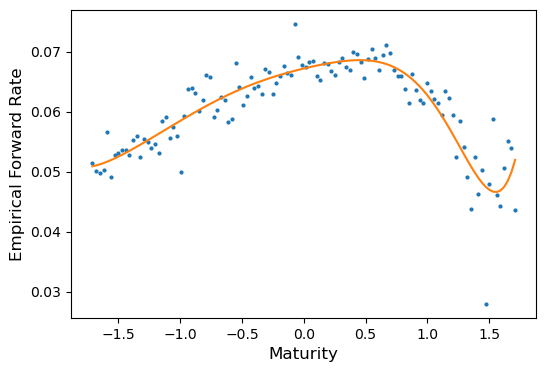

In [9]:
X_with_ones = Xfull_with_ones[:,[0,1,2,4,5,7,8]]

FSWoptmodel = sm.OLS(endog=forratedat['emp'],exog=X_with_ones).fit()

fig, axs = plt.subplots(1, 1, figsize=[6,4])
axs.plot(forratedat['maturity'],forratedat['emp'],marker='.', ms=4, linestyle="none")
axs.set_xlabel("Maturity", size=12)
axs.set_ylabel("Empirical Forward Rate", size=12)
axs.plot(forratedat['maturity'], FSWoptmodel.fittedvalues,ms=10)
plt.show()

\newpage

## Other Information Criteria {-}

$R^2$ monotonically increases as more predictors are added. **Adjusted $R^2$** corrects for this by scaling the components by their respective degrees of freedom, penalizing the addition of predictors. It imposes a weak penalty on complexity, and is generally not recommended.
\begin{equation*}
R^2_{adj} = 1 - \left[ \frac{(1 - R^2)(n - 1)}{n - k - 1} \right]
\end{equation*}

The **Bayesian Information Criterion (BIC)**, also known as the **Schwarz criterion**, applies a stricter penalty for complexity that does AIC, strongly favoring parsimony. It is possible to show that, under certain assumptions, if the true model is within the class under consideration, BIC will choose it with probability that converges to one as $n$ grows.
\begin{equation}
\text{BIC} = n \log\left(\frac{RSS}{n}\right) + p \log(n)
\end{equation}

**Mallows' $C_p$** is an estimator of the expected prediction error. It attempts to correct for the downward bias of the training residual error by adding a penalty proportional to the number of parameters and the variance of the true underlying model. It has been shown that Mallows' $C_p$ and AIC are very similar, especially for large $n$.

\begin{equation*}
C_p = \frac{RSS}{\hat{\sigma}^2} - n + 2p
\end{equation*}

\newpage

## Cross Validation {-}

We've discussed the use of AIC for the purpose of
predictor selection.

An important alternative is **leave-one-out cross validation**.

In this approach, one imagines refitting the model $n$ times,
each time excluding one of the $n$ observations. 

At iteration $i$, observation $i$ is excluded. The fitted model
is then used to predict the response for this observation. 
Call this $\widehat y_{(-i)}$.

Finally, we calculate the quantity
\begin{equation*}
   {\rm PRESS} = \sum_{i=1}^n \left(y_i -\widehat y_{(-i)}\right)^2
\end{equation*}
where **PRESS** stands for **Prediction Error Sum of Squares**.

\newpage

The motivation for this is as follows: Once observation $i$ is removed
from the fit, we have removed the **influence** that this observation
has on the parameter estimates.

Now, we can think of observation $i$ as being a "new" observation,
and we can ask: "How well does the model, containing only these predictors,
predict the response for this case?" 

The quantity $(y_i - \widehat y_{(-i)})^2$ quantifies the amount of error in this
prediction.

**Exercise:** Which is larger: PRESS or RSS?

\answerlines{9}

\newpage

Fortunately, it is not actually necessary to fit $n$ models in order 
calculate PRESS.

The remarkable result is as follows:

Let ${\bf Y}$ be a vector consisting of the $n$ responses, and
let $\widehat {\bf Y}$ be a vector consisting of the $n$ fitted
values (from the full model).

If it is the case that $\widehat {\bf Y} = {\bf H} {\bf Y}$, then 
\begin{equation*}
   y_i - \widehat y_{(-i)} = \frac{\widehat \epsilon_i}{1-h_{ii}} 
\end{equation*}
where $h_{ii}$ is the $i^{th}$ diagonal element of ${\bf H}$.

In the case of linear regression, it is the case that
\begin{equation*}
   {\bf H} = {\bf X} \left({\bf X}^T{\bf X}\right)^{-1} {\bf X}^T
\end{equation*}
where ${\bf X}$ whose columns hold the values of the predictors.
See Ruppert and Matteson for the details.

This matrix ${\bf H}$ is previously mentioned **hat matrix**.

The diagonal elements $h_{ii}$ are called the **leverages**.

\newpage

The leverages can be found in Python using the following.

In [10]:
import statsmodels.stats.outliers_influence as outliers_influence

levs = outliers_influence.OLSInfluence(fullmod).hat_matrix_diag

and then PRESS can be calculated as

In [11]:
PRESS = ((fullmod.resid / (1 - levs))**2).sum()
print(PRESS)

0.0019740282761601343


\newpage

The following code performs an exhaustive search for the optimal model when using PRESS.

In [12]:
df2 = {}

for k in tnrange(1, len(Xfull.columns)+1):
    for combo in itertools.combinations(Xfull.columns, k):
        X_with_ones = sm.add_constant(Xfull[list(combo)])
        model = sm.OLS(endog=forratedat['emp'], exog=X_with_ones).fit()
        levs = outliers_influence.OLSInfluence(model).hat_matrix_diag
        df2[str(combo)] = ((model.resid / (1 - levs))**2).sum()
        
df2 = pd.Series(df2)

  0%|          | 0/9 [00:00<?, ?it/s]

In [13]:
df2.idxmin()

'(1, 3, 4, 6, 7)'

The resulting model fit is
\begin{equation*}
   Y_i = \beta_0 + \beta_1 T_i + \beta_3 T_i^3 + \beta_4 T_i^4 + \beta_6 T_i^6 + \beta_7 T_i^7 + \epsilon_i
\end{equation*}
This is, again, a sightly different model, but it yields almost identical predictions for the response.

\newpage

## AIC versus PRESS {-}

AIC and PRESS will often give similar, if not the same, result for the
model choice.

There are a couple main reasons to prefer
PRESS to AIC: First, the quantity being estimated is by PRESS
is a very natural measure of prediction performance. Second, the
theory behind AIC is based on the assumption that the disributional
assumption for the errors is correct.

One reason to choose AIC over PRESS is that AIC is more
stable. 
The estimate
that PRESS provides of the expected prediction error is subject
to large variance. Hence, PRESS may
not perform well for small to moderate sample sizes.

Although PRESS is simple to calculate in the case of linear
regression, this will not always be the case. In general,
AIC will be easier to calculate than PRESS.

Also,
the cross-validation approach described here assumes that observations
are iid, i.e., that removing one (or more) observations leaves a smaller
sample, but one that is still of fundamentally the same structure as the
original training set. AIC requires there be a likelihood function, but
not that the observations be iid.
For example, cross-validation with time series
data is more complicated, but AIC is widely used.

As is often the case, our past experience will often guide our
choice of criterion.